# Episode 6: The Gradient and the Step
<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/Episode%2006%20-%20The%20Gradient%20and%20the%20Step/notebook.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*. Calculus for Learning, part 2 of 2.

The episode works every calculation by hand. This notebook does the same calculations in the same order, prints each line the way it appears on screen, and checks every value with an `assert`. It uses only `numpy` and `matplotlib` (both already in Colab): choose **Runtime, Run all**.

| Part | What you'll compute | Video numbers |
|---|---|---|
| 1 | Partial derivatives and the gradient: the four-word softmax gradient, then the bowl | −0.70, +0.20, +0.15, +0.35 · f = 3 · ∇f = (2, 4) · √20 ≈ 4.47 |
| 2 | Why the gradient is steepest: three directions by hand, then 3,600 directions | 2 · 4 · 4.47 |
| 3 | The gradient step: a small one, a greedy one, the curve derived by hand, and its limits | 1.36 · 19 · 3 − 20η + 36η² · 0.556 · 0.278 → 0.222 |
| 4 | The myth "the gradient points to the bottom", one picture of everything, and the check question | 18.4° · (4, 4) · 5.66 |
| 5 | Try it yourself, with self-checks | 2 · 3.96 · 4.24 · your numbers |

Episode 1's four-word probabilities (mat 0.30, floor 0.20, sofa 0.15, other 0.35, after “The cat sat on the”) are **illustrative**. Episode 5 found the slope of mat's surprisal with respect to mat's score: −0.70. Logs are natural (nats).

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np

STEEL, GOLD, CORAL, MUTED = "#8FB4E8", "#FFC400", "#FF4D3D", "#8B98AE"   # the video's colours

words = ["mat", "floor", "sofa", "other"]
p = np.array([0.30, 0.20, 0.15, 0.35])        # illustrative, from Episode 1


def fmt(x):
    """Print a number the way you would write it on paper: 0.64, not 0.6400000000000001."""
    return f"{round(float(x), 8):.10g}"


def softmax(h):
    """Stable softmax (Episode 4): subtract the largest score first."""
    h = np.asarray(h, dtype=float)
    e = np.exp(h - h.max())
    return e / e.sum()


def surprisal(x):
    """-ln p, in nats (Episode 4)."""
    return -np.log(x)


def slope_numeric(f, z, h=1e-6):
    """Central difference: the slope of f at z, measured with a tiny step on each side."""
    return (f(z + h) - f(z - h)) / (2 * h)

## Part 1 · Partial derivatives and the gradient

A model has many numbers, not one, so we need slopes in many directions at once. The **partial derivative** ∂f/∂z₁ measures how f changes when only z₁ moves, with everything else frozen. Collect all the partials into one vector: that is the **gradient**, ∇f.

### Step 1: your first real gradient, from softmax
You can't push one probability up on its own: under softmax, if mat goes up the others go down, so the total stays 1. The knob is the score. Take mat's surprisal as a function of all four scores (h = ln p, so softmax gives back p), and find its partial derivative with respect to each score. Mat's is Episode 5's −(1 − p) = −0.70; for each other word it is that word's probability. Each slope is checked by nudging that one score and measuring.

In [2]:
h = np.log(p)


def mat_surprisal(scores):
    return surprisal(softmax(scores)[0])


onehot = np.array([1.0, 0, 0, 0])
grad_formula = softmax(h) - onehot           # dS/dh_j = p_j - 1 for mat, p_j for the others
grad_numeric = np.array([slope_numeric(lambda t, j=j: mat_surprisal(h + t * np.eye(4)[j]), 0.0) for j in range(4)])
for w, a, b in zip(words, grad_formula, grad_numeric):
    print(f"{w:6s} slope {a:+.2f}   (nudge check {b:+.4f})")
print(f"sum: {grad_formula.sum():+.2f}")
assert np.allclose(softmax(h), p) and np.isclose(grad_formula[0], -(1 - 0.30))
assert np.allclose(np.round(grad_formula, 2), [-0.70, 0.20, 0.15, 0.35])
assert np.allclose(grad_numeric, grad_formula, atol=1e-6) and np.isclose(grad_formula.sum(), 0)
print("This pattern (probability minus target) comes back in Episode 13, as backpropagation.")

mat    slope -0.70   (nudge check -0.7000)
floor  slope +0.20   (nudge check +0.2000)
sofa   slope +0.15   (nudge check +0.1500)
other  slope +0.35   (nudge check +0.3500)
sum: +0.00
This pattern (probability minus target) comes back in Episode 13, as backpropagation.


### Step 2: the bowl
Our test landscape: f(z₁, z₂) = z₁² + 2z₂². By the power rule, ∂f/∂z₁ = 2z₁ and ∂f/∂z₂ = 4z₂ (the 2 out front doubles 2z₂). Seen from above, the contour lines are ellipses around the bottom at (0, 0). Stand at (1, 1).

In [3]:
def bowl(z):
    z = np.asarray(z, dtype=float)
    return z[..., 0] ** 2 + 2 * z[..., 1] ** 2


def grad_bowl(z):
    z = np.asarray(z, dtype=float)
    return np.array([2 * z[0], 4 * z[1]])


def bowl_by_hand(z):
    a, b = z
    sa, sb = (f"({fmt(v)})" if v < 0 else fmt(v) for v in (a, b))
    print(f"f = {sa}^2 + 2 x {sb}^2 = {fmt(a * a)} + 2 x {fmt(b * b)} = {fmt(a * a)} + {fmt(2 * b * b)} = {fmt(bowl(z))}")
    return bowl(z)


start = np.array([1.0, 1.0])
f_start = bowl_by_hand(start)
g = grad_bowl(start)
print(f"df/dz1 = 2 x 1 = {fmt(g[0])},  df/dz2 = 4 x 1 = {fmt(g[1])}   ->  grad f = ({fmt(g[0])}, {fmt(g[1])})")
norm = np.linalg.norm(g)
print(f"length: sqrt({fmt(g[0])}^2 + {fmt(g[1])}^2) = sqrt({fmt(g[0]**2)} + {fmt(g[1]**2)}) = sqrt({fmt(g @ g)}) = {norm:.2f}")
assert f_start == 3 and np.allclose(g, [2, 4]) and g @ g == 20 and round(norm, 2) == 4.47
for j in range(2):                            # each partial: change only that coordinate, freeze the other
    assert np.isclose(slope_numeric(lambda t, j=j: bowl(start + t * np.eye(2)[j]), 0.0), g[j])
print("each partial checked by moving only that coordinate")

f = 1^2 + 2 x 1^2 = 1 + 2 x 1 = 1 + 2 = 3
df/dz1 = 2 x 1 = 2,  df/dz2 = 4 x 1 = 4   ->  grad f = (2, 4)
length: sqrt(2^2 + 4^2) = sqrt(4 + 16) = sqrt(20) = 4.47
each partial checked by moving only that coordinate


## Part 2 · Why the gradient is steepest

### Step 3: three directions by hand
The slope in a unit direction a is the gradient dotted with a: D_a f = ∇f · a. Try three directions from (1, 1), and measure each one by actually stepping a tiny distance that way.

In [4]:
def direction_by_hand(a, work):
    a = np.asarray(a, dtype=float)
    s = g @ a
    measured = slope_numeric(lambda t: bowl(start + t * a), 0.0)
    print(f"{work:50s} = {s:.2f}   (measured {measured:.2f})")
    assert np.isclose(np.linalg.norm(a), 1) and np.isclose(measured, s)
    return s


along_z1 = direction_by_hand([1, 0], "a = (1, 0):        2 x 1 + 4 x 0")
along_z2 = direction_by_hand([0, 1], "a = (0, 1):        2 x 0 + 4 x 1")
along_g = direction_by_hand(g / norm, f"a = (2, 4)/{norm:.2f}:  (2 x 2 + 4 x 4) / {norm:.2f} = 20 / {norm:.2f}")
print("along the gradient is steeper than both")
assert along_z1 == 2 and along_z2 == 4 and round(along_g, 2) == 4.47 and along_g > along_z2

a = (1, 0):        2 x 1 + 4 x 0                   = 2.00   (measured 2.00)
a = (0, 1):        2 x 0 + 4 x 1                   = 4.00   (measured 4.00)
a = (2, 4)/4.47:  (2 x 2 + 4 x 4) / 4.47 = 20 / 4.47 = 4.47   (measured 4.47)
along the gradient is steeper than both


### Step 4: why steepest
From Episode 2, a dot product is the two lengths times the cosine of the angle between them: D_a f = ‖∇f‖ cos φ for a unit a. It is biggest at φ = 0. So ∇f points straight uphill, and −∇f points steepest downhill. Below we try 3,600 unit directions around (1, 1), measure each slope by stepping, and find the steepest one.

Fine print: f must be smooth there, ∇f must not be zero (at a flat point it has no direction at all, and saddle points are flat too), and "steepest" assumes ordinary Euclidean distance.

In [5]:
angles = np.linspace(0, 2 * np.pi, 3600, endpoint=False)
dirs = np.stack([np.cos(angles), np.sin(angles)], axis=1)          # 3600 unit vectors
eps = 1e-6
measured = (bowl(start + eps * dirs) - bowl(start - eps * dirs)) / (2 * eps)
best = dirs[np.argmax(measured)]
print(f"steepest measured slope: {measured.max():.2f}  (length of grad f: {norm:.2f})")
print(f"steepest direction: ({best[0]:.3f}, {best[1]:.3f});  grad f / |grad f| = ({g[0]/norm:.3f}, {g[1]/norm:.3f})")
for deg in (0, 45, 90, 180):
    a = np.array([np.cos(np.radians(deg)), np.sin(np.radians(deg))])
    rot = np.array([[a[0], -a[1]], [a[1], a[0]]]) @ (g / norm)       # turn grad's direction by deg
    print(f"  phi = {deg:3d} deg: slope = |grad f| cos phi = {norm:.2f} x {np.cos(np.radians(deg)):+.2f} = {g @ rot:+.2f}")
assert np.allclose(measured, dirs @ g, atol=1e-5)                    # D_a f = grad f . a
assert np.isclose(measured.max(), norm, atol=1e-4) and np.allclose(best, g / norm, atol=1e-3)
assert np.isclose(measured.min(), -norm, atol=1e-4)                  # -grad f: steepest downhill

steepest measured slope: 4.47  (length of grad f: 4.47)
steepest direction: (0.448, 0.894);  grad f / |grad f| = (0.447, 0.894)
  phi =   0 deg: slope = |grad f| cos phi = 4.47 x +1.00 = +4.47
  phi =  45 deg: slope = |grad f| cos phi = 4.47 x +0.71 = +3.16
  phi =  90 deg: slope = |grad f| cos phi = 4.47 x +0.00 = +0.00
  phi = 180 deg: slope = |grad f| cos phi = 4.47 x -1.00 = -4.47


## Part 3 · The gradient step

Move from z to z − η∇f. η (eta) is the step size; Episode 8 will call it the learning rate. Goodfellow, Bengio and Courville put the catch plainly: this lowers f *for a small enough step*. `gradient_step_by_hand` prints the video's worksheet.

### Step 5: a small step and a greedy one

In [6]:
def gradient_step_by_hand(f, grad, z, eta, show=None):
    z = np.asarray(z, dtype=float)
    gz = grad(z)
    step = eta * gz
    new = z - step
    print(f"eta = {fmt(eta)} from ({fmt(z[0])}, {fmt(z[1])}), f = {fmt(f(z))}")
    print(f"  eta x grad f = {fmt(eta)} x ({fmt(gz[0])}, {fmt(gz[1])}) = ({fmt(step[0])}, {fmt(step[1])})")
    print(f"  new point: ({fmt(z[0])} - {fmt(step[0])}, {fmt(z[1])} - {fmt(step[1])}) = ({fmt(new[0])}, {fmt(new[1])})")
    if show is not None:
        print("  ", end="")
        show(new)
    fn = f(new)
    print(f"  {'DOWN' if fn < f(z) else 'UP'} from {fmt(f(z))} to {fmt(fn)}\n")
    return new, fn


small, f_small = gradient_step_by_hand(bowl, grad_bowl, start, 0.1, show=bowl_by_hand)
greedy, f_greedy = gradient_step_by_hand(bowl, grad_bowl, start, 1.0, show=bowl_by_hand)
assert np.allclose(0.1 * g, [0.2, 0.4]) and np.allclose(small, [0.8, 0.6])
assert np.isclose(0.8 ** 2, 0.64) and np.isclose(2 * 0.6 ** 2, 0.72) and np.isclose(f_small, 1.36)
assert np.allclose(greedy, [-1, -3]) and np.isclose(f_greedy, 19) and f_greedy > f_start
print("One step against the gradient, and we went uphill: 3 -> 19.")

eta = 0.1 from (1, 1), f = 3
  eta x grad f = 0.1 x (2, 4) = (0.2, 0.4)
  new point: (1 - 0.2, 1 - 0.4) = (0.8, 0.6)
  f = 0.8^2 + 2 x 0.6^2 = 0.64 + 2 x 0.36 = 0.64 + 0.72 = 1.36
  DOWN from 3 to 1.36

eta = 1 from (1, 1), f = 3
  eta x grad f = 1 x (2, 4) = (2, 4)
  new point: (1 - 2, 1 - 4) = (-1, -3)
  f = (-1)^2 + 2 x (-3)^2 = 1 + 2 x 9 = 1 + 18 = 19
  UP from 3 to 19

One step against the gradient, and we went uphill: 3 -> 19.


### Step 6: the height along the line, derived by hand
After a step of size η from (1, 1), the point is (1 − 2η, 1 − 4η). The height is the first coordinate squared plus two times the second squared:

- (1 − 2η)² = 1 − 4η + 4η²
- (1 − 4η)² = 1 − 8η + 16η², doubled: 2 − 16η + 32η²
- add them: **f(η) = 3 − 20η + 36η²**

The cell redoes the algebra with polynomials stored as lists of coefficients (highest power first), so each line is an exact check of the hand expansion, then compares the result with the real bowl at 400 step sizes.

In [7]:
def poly_str(c):
    """[36, -20, 3] -> '36η² - 20η + 3', written in the video's order: constant first."""
    terms = []
    for power, k in zip([2, 1, 0], c):
        if k:
            terms.append((fmt(k), {2: "η²", 1: "η", 0: ""}[power]))
    out = ""
    for num, var in reversed(terms):
        s = f"{num}{var}"
        out += s if not out else (f" - {s[1:]}" if s.startswith("-") else f" + {s}")
    return out


first = np.polymul([-2, 1], [-2, 1])          # (1 - 2η)^2
second = np.polymul([-4, 1], [-4, 1])         # (1 - 4η)^2
doubled = 2 * second
total = np.polyadd(first, doubled)
print(f"(1 - 2η)²         = {poly_str(first)}")
print(f"(1 - 4η)²         = {poly_str(second)}")
print(f"2 x (1 - 4η)²     = {poly_str(doubled)}")
print(f"sum: f(η)         = {poly_str(total)}")
assert list(first) == [4, -4, 1] and list(second) == [16, -8, 1] and list(doubled) == [32, -16, 2]
assert list(total) == [36, -20, 3]


def f_along(eta):
    return 3 - 20 * eta + 36 * eta ** 2


etas = np.linspace(0, 1.05, 400)
assert np.allclose(f_along(etas), bowl(start - etas[:, None] * g))          # the formula matches the bowl
assert np.allclose(np.polyfit(etas, bowl(start - etas[:, None] * g), 2), [36, -20, 3])
print(f"\nthe 20 is grad f . grad f = {fmt(g @ g)}: the downhill pull;  36η² is the curvature term")
print(f"check eta = 0.1: 3 - 2 + 0.36 = {f_along(0.1):.2f}")
print(f"check eta = 1:   3 - 20 + 36 = {f_along(1):.0f}      (both steps, from one formula)")
assert g @ g == 20 and np.isclose(f_along(0.1), 1.36) and np.isclose(f_along(1), 19)

(1 - 2η)²         = 1 - 4η + 4η²
(1 - 4η)²         = 1 - 8η + 16η²
2 x (1 - 4η)²     = 2 - 16η + 32η²
sum: f(η)         = 3 - 20η + 36η²

the 20 is grad f . grad f = 20: the downhill pull;  36η² is the curvature term
check eta = 0.1: 3 - 2 + 0.36 = 1.36
check eta = 1:   3 - 20 + 36 = 19      (both steps, from one formula)


### Step 7: the limits, by hand
The height comes back up to 3 when 36η² = 20η. Divide by η: η = 20/36. Any longer step lands higher than you started. The best step sits exactly halfway between 0 and 20/36, at 20/72.

back to 3 when 36η² = 20η  ->  η = 20/36 = 0.556
best step, halfway: 20/72 = 0.278
height there: 3 - 5.56 + 2.78 = 0.222


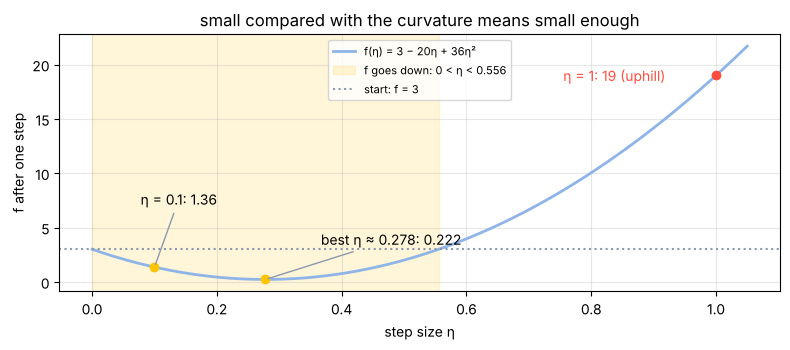

In [8]:
eta_max, eta_best = 20 / 36, 20 / 72
f_best = f_along(eta_best)
print(f"back to 3 when 36η² = 20η  ->  η = 20/36 = {eta_max:.3f}")
print(f"best step, halfway: 20/72 = {eta_best:.3f}")
print(f"height there: 3 - {20 * eta_best:.2f} + {36 * eta_best ** 2:.2f} = {f_best:.3f}")
assert round(eta_max, 3) == 0.556 and round(eta_best, 3) == 0.278 and round(f_best, 3) == 0.222
assert round(20 * eta_best, 2) == 5.56 and round(36 * eta_best ** 2, 2) == 2.78
assert np.isclose(f_along(eta_max), 3) and abs(etas[np.argmin(f_along(etas))] - eta_best) < 0.005
assert np.all(f_along(etas[(etas > 0) & (etas < eta_max)]) < 3) and np.all(f_along(etas[etas > eta_max]) > 3)

plt.figure(figsize=(8, 3.6))
plt.plot(etas, f_along(etas), color=STEEL, lw=2, label="f(η) = 3 − 20η + 36η²")
plt.axvspan(0, eta_max, color=GOLD, alpha=0.15, label="f goes down: 0 < η < 0.556")
plt.axhline(3, color=MUTED, ls=":", label="start: f = 3")
plt.plot([0.1], [1.36], "o", color=GOLD)
plt.plot([eta_best], [f_best], "o", color=GOLD)
plt.plot([1], [19], "o", color=CORAL)
plt.annotate("η = 0.1: 1.36", (0.1, 1.36), textcoords="offset points", xytext=(-10, 45), arrowprops={"arrowstyle": "-", "color": MUTED})
plt.annotate("best η ≈ 0.278: 0.222", (eta_best, f_best), textcoords="offset points", xytext=(40, 25), arrowprops={"arrowstyle": "-", "color": MUTED})
plt.annotate("η = 1: 19 (uphill)", (1, 19), textcoords="offset points", xytext=(-110, -4), color=CORAL)
plt.xlabel("step size η"); plt.ylabel("f after one step")
plt.title("small compared with the curvature means small enough")
plt.grid(alpha=0.3); plt.legend(loc="upper center", fontsize=8)
plt.tight_layout()
plt.show()

Goodfellow et al. (§4.3.1): if the curvature term is too large, "the gradient descent step can actually move uphill". That is the hiker in the fog who takes one giant leap downhill, sails over the valley floor and lands higher on the far slope. Her map is only the ground under her boots.

## Part 4 · The myth: "the gradient points to the bottom"

Near any point, stepping against the gradient does go down. But at (1, 1), compare −∇f = (−2, −4) with the direction to the bottom, (−1, −1).

In [9]:
down = -g
to_bottom = np.zeros(2) - start
dot = down @ to_bottom
lengths = np.linalg.norm(down) * np.linalg.norm(to_bottom)
cos_phi = dot / lengths
angle = np.degrees(np.arccos(cos_phi))
print(f"-grad f = ({fmt(down[0])}, {fmt(down[1])}),  to the bottom = ({fmt(to_bottom[0])}, {fmt(to_bottom[1])})")
print(f"dot product: ({fmt(down[0])})({fmt(to_bottom[0])}) + ({fmt(down[1])})({fmt(to_bottom[1])}) = 2 + 4 = {fmt(dot)}")
print(f"lengths: sqrt(20) x sqrt(2) = sqrt(40) = {lengths:.3f}")
print(f"cos = {fmt(dot)} / {lengths:.3f} = {cos_phi:.3f}  ->  angle = {angle:.1f} degrees")
assert dot == 6 and round(lengths, 3) == 6.325 and round(cos_phi, 3) == 0.949 and round(angle, 1) == 18.4

# steepest-down is square to the contour line through (1, 1)
tangent_to_contour = np.array([-g[1], g[0]])
assert np.isclose(tangent_to_contour @ down, 0)

-grad f = (-2, -4),  to the bottom = (-1, -1)
dot product: (-2)(-1) + (-4)(-1) = 2 + 4 = 6
lengths: sqrt(20) x sqrt(2) = sqrt(40) = 6.325
cos = 6 / 6.325 = 0.949  ->  angle = 18.4 degrees


### One picture of everything
The contours f = 1.36, 3 and 19 pass through the three points we computed. ∇f (steel) points uphill, −∇f (gold) steepest downhill, square to the contour, and the dashed line to the bottom is 18.4° away from it. The small step lands inside the f = 3 ellipse; the greedy step overshoots onto f = 19.

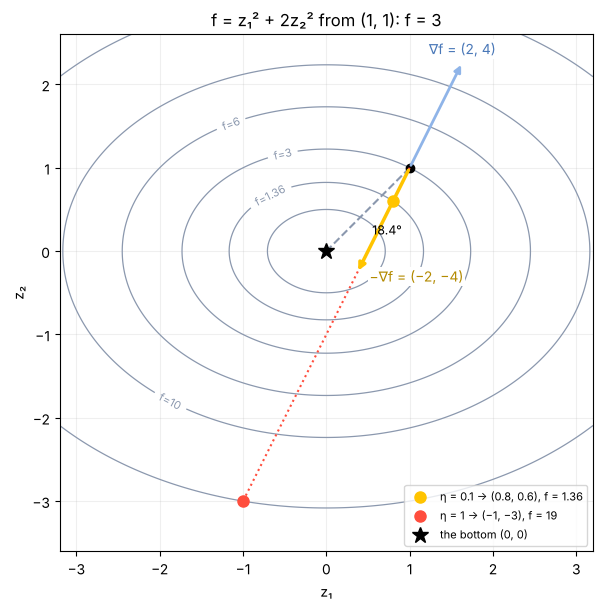

In [10]:
x1, x2 = np.meshgrid(np.linspace(-3.2, 3.2, 300), np.linspace(-3.6, 2.6, 300))
F = x1 ** 2 + 2 * x2 ** 2
fig, ax = plt.subplots(figsize=(6.4, 6.2))
cs = ax.contour(x1, x2, F, levels=[0.5, 1.36, 3, 6, 10, 19], colors=MUTED, linewidths=0.9)
ax.clabel(cs, levels=[1.36, 3, 6, 10], fmt="f=%g", fontsize=8)
u = g / norm * np.sqrt(2)                      # draw both arrows as long as the path to the bottom
ax.annotate("", xy=start + u, xytext=start, arrowprops={"arrowstyle": "-|>", "color": STEEL, "lw": 2})
ax.annotate("", xy=start - u, xytext=start, arrowprops={"arrowstyle": "-|>", "color": GOLD, "lw": 2.5})
ax.plot([1, 0], [1, 0], "--", color=MUTED, lw=1.5)
ax.text(1 + u[0], 1 + u[1] + 0.1, "∇f = (2, 4)", color="#4A78B8", ha="center",
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.text(start[0] - u[0] + 0.15, start[1] - u[1] - 0.1, "−∇f = (−2, −4)", color="#B38A00", ha="left",
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.text(0.55, 0.2, f"{angle:.1f}°", fontsize=9)
ax.plot(*start, "o", color="k")
ax.plot(*small, "o", color=GOLD, ms=8, label="η = 0.1 → (0.8, 0.6), f = 1.36")
ax.plot(*greedy, "o", color=CORAL, ms=8, label="η = 1 → (−1, −3), f = 19")
ax.plot([1, greedy[0]], [1, greedy[1]], ":", color=CORAL)
ax.plot(0, 0, "*", color="k", ms=12, label="the bottom (0, 0)")
ax.set_aspect("equal"); ax.set_xlabel("z₁"); ax.set_ylabel("z₂")
ax.set_title("f = z₁² + 2z₂² from (1, 1): f = 3")
ax.legend(loc="lower right", fontsize=8); ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

The gradient is local: it knows the slope here, not the shape over the next hill, and at a flat point it gives no direction at all. **The gradient tells you which way is down from here. It does not tell you where the bottom is.**

### Check question
Same bowl, at (2, 1). (a) What is the gradient? (b) Which unit direction lowers f fastest? (c) Roughly how much does f fall per unit of distance moved that way?

In [11]:
q = np.array([2.0, 1.0])
gq = grad_bowl(q)
fastest = -gq / np.linalg.norm(gq)
rate = (bowl(q) - bowl(q + 1e-6 * fastest)) / 1e-6
print(f"(a) grad f = (2 x 2, 4 x 1) = ({fmt(gq[0])}, {fmt(gq[1])})")
print(f"(b) (-1, -1) / sqrt(2) = ({fastest[0]:.3f}, {fastest[1]:.3f})")
print(f"(c) |grad f| = sqrt(16 + 16) = sqrt(32) = {np.linalg.norm(gq):.2f} per unit distance (measured: {rate:.2f})")
assert np.allclose(gq, [4, 4]) and np.allclose(fastest, np.array([-1, -1]) / np.sqrt(2))
assert round(np.linalg.norm(gq), 2) == 5.66 and np.isclose(rate, np.sqrt(32), atol=1e-4)

(a) grad f = (2 x 2, 4 x 1) = (4, 4)
(b) (-1, -1) / sqrt(2) = (-0.707, -0.707)
(c) |grad f| = sqrt(16 + 16) = sqrt(32) = 5.66 per unit distance (measured: 5.66)


## Part 5 · Try it yourself
Change the values in the next cells and re-run them. The self-checks tell you whether your own hand calculation matches.

1. From (1, 1), try η = 0.5 and η = 0.6 with the formula 3 − 20η + 36η². Which side of 3 does each land on? Check against the line 0.556.
2. Run gradient descent with your own step size and watch it settle, or blow up.
3. Find the slope in the direction (1, 1)/√2, by hand. Type it into `my_slope`.

In [12]:
my_etas = [0.5, 0.6]                   # 1. your step sizes from (1, 1)
for eta in my_etas:
    _, f_new = gradient_step_by_hand(bowl, grad_bowl, start, eta, show=bowl_by_hand)
    print(f"  formula: 3 - {fmt(20 * eta)} + {fmt(36 * eta ** 2)} = {fmt(f_along(eta))}\n")
    assert np.isclose(f_new, f_along(eta)) and ((f_new < 3) == (0 < eta < eta_max))
if my_etas == [0.5, 0.6]:
    assert np.isclose(f_along(0.5), 2) and np.isclose(f_along(0.6), 3.96)
    print("eta = 0.5: 3 - 10 + 9 = 2 (down);  eta = 0.6: 3 - 12 + 12.96 = 3.96 (up, past 0.556)")

eta = 0.5 from (1, 1), f = 3
  eta x grad f = 0.5 x (2, 4) = (1, 2)
  new point: (1 - 1, 1 - 2) = (0, -1)
  f = 0^2 + 2 x (-1)^2 = 0 + 2 x 1 = 0 + 2 = 2
  DOWN from 3 to 2

  formula: 3 - 10 + 9 = 2

eta = 0.6 from (1, 1), f = 3
  eta x grad f = 0.6 x (2, 4) = (1.2, 2.4)
  new point: (1 - 1.2, 1 - 2.4) = (-0.2, -1.4)
  f = (-0.2)^2 + 2 x (-1.4)^2 = 0.04 + 2 x 1.96 = 0.04 + 3.92 = 3.96
  UP from 3 to 3.96

  formula: 3 - 12 + 12.96 = 3.96

eta = 0.5: 3 - 10 + 9 = 2 (down);  eta = 0.6: 3 - 12 + 12.96 = 3.96 (up, past 0.556)


**Run gradient descent yourself.** Pick a step size and a number of steps and watch f, step by step. Each step multiplies z₁ by (1 − 2η) and z₂ by (1 − 4η), so over *many* steps this bowl needs 0 < η < 0.5 to keep shrinking (the 0.556 above is for one step from (1, 1)). Try 0.1, 0.25, 0.45, 0.53 and 0.6.

step  1: z = (+0.8000, +0.6000)   f = 1.3600
step  2: z = (+0.6400, +0.3600)   f = 0.6688
step  3: z = (+0.5120, +0.2160)   f = 0.3555
step  4: z = (+0.4096, +0.1296)   f = 0.2014
step  5: z = (+0.3277, +0.0778)   f = 0.1195
step  6: z = (+0.2621, +0.0467)   f = 0.0731
step  7: z = (+0.2097, +0.0280)   f = 0.0455
step  8: z = (+0.1678, +0.0168)   f = 0.0287
step  9: z = (+0.1342, +0.0101)   f = 0.0182
step 10: z = (+0.1074, +0.0060)   f = 0.0116


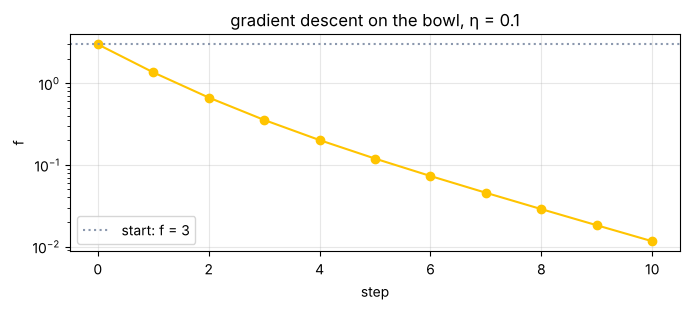

In [13]:
my_eta, my_steps = 0.1, 10             # 2. your step size and number of steps

z = start.copy()
history = [bowl(z)]
for k in range(1, my_steps + 1):
    z = z - my_eta * grad_bowl(z)
    history.append(bowl(z))
    print(f"step {k:2d}: z = ({z[0]:+.4f}, {z[1]:+.4f})   f = {history[-1]:.4f}")
assert np.allclose(z, start * np.array([(1 - 2 * my_eta), (1 - 4 * my_eta)]) ** my_steps)
if 0 < my_eta < 0.5:
    assert np.all(np.diff(history) < 0)       # every step goes down
if my_eta == 0.1:
    assert np.isclose(history[1], 1.36)

plt.figure(figsize=(7, 3.2))
plt.plot(range(my_steps + 1), history, "o-", color=GOLD if history[-1] < history[0] else CORAL)
plt.axhline(3, color=MUTED, ls=":", label="start: f = 3")
if max(history) / max(min(history), 1e-12) > 100:
    plt.yscale("log")
plt.xlabel("step"); plt.ylabel("f"); plt.title(f"gradient descent on the bowl, η = {my_eta}")
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.show()

In [14]:
my_slope = None                        # 3. your slope in the direction (1, 1)/sqrt(2), e.g. 4.24

a = np.array([1, 1]) / np.sqrt(2)
by_hand = (2 * 1 + 4 * 1) / np.sqrt(2)
measured_a = slope_numeric(lambda t: bowl(start + t * a), 0.0)
print(f"(2 x 1 + 4 x 1) / sqrt(2) = 6 / {np.sqrt(2):.3f} = {by_hand:.2f}   (measured {measured_a:.2f})")
print(f"less than the steepest, {norm:.2f}: (1, 1) is {np.degrees(np.arccos(g @ a / norm)):.1f} degrees away from grad f")
if my_slope is not None:
    print("your answer matches" if np.isclose(my_slope, by_hand, atol=0.01) else f"not quite: the dot product gives {by_hand:.2f}")
assert round(by_hand, 2) == 4.24 and np.isclose(measured_a, by_hand) and by_hand < norm

(2 x 1 + 4 x 1) / sqrt(2) = 6 / 1.414 = 4.24   (measured 4.24)
less than the steepest, 4.47: (1, 1) is 18.4 degrees away from grad f


In [15]:
print("All Episode 6 checks passed.")

All Episode 6 checks passed.
